# Stromal cell types across age groups - composition, UMAP and frequency change

Stroma = `taa_l1 in {TEC, Fb, EC, Mural}`, at three annotation levels (`taa_l1`, `taa_l2_v2`, `taa_l3`),
age groups **infant / paed / adult** (`aged` removed). Object:
`thyAgeing_all_scvi_v6_2026-05-01.zarr` (obs + embeddings only - no counts needed), cell types from
`curatedAnno_v11`.

1. **Stacked bars** in the style of the TEC frequency figure - top panel = stroma as a proportion of all
   cells (mean +/- sd across donors, unsorted `TOT` samples); bottom = stacked relative frequency within
   stroma, from **`TOT` + `CD45N` samples with >= 100 stromal cells** each (donor is the averaging unit, so
   a donor sampled in both brackets counts once). A diagnostics section first reports what each sort
   bracket gives on its own, and a sensitivity section repeats the figures with `CD45N` only, the wider
   stroma-enriched bracket and `TOT` only.
2. **UMAP** of the stromal cells, coloured with the *same palette as the bars*, embedding and plot
   settings from `notebooks_github/08_TEC-EMT.ipynb`.
3. **Frequency change with age** quantified as in
   `notebooks_github/03_Frequency_analysis_TEC_v3.ipynb` (per-donor frequencies, Kruskal-Wallis per cell
   type + post-hoc Dunn, annotated boxplots) with pink boxes per age group.

Plotting code: `General_analysis/scripts/plotting/pop_stacked.py` (generalised version of
`plotting.utils.population_stacked_plot`, which hardcodes the four age groups and the `TOT` sort).

In [1]:
import sys, os
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import hdf5plugin  # required to read the blosc-compressed v6 object
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import rcParams, font_manager

In [2]:
repo_path = '/nfs/team205/vk8/projects/thymus_ageing_atlas'
sys.path.insert(1, f'{repo_path}/General_analysis/scripts')

%reload_ext autoreload
%autoreload 2

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
pd.set_option('display.max_columns', None)
pd.options.display.max_rows = 100

In [3]:
rcParams['pdf.fonttype'] = 42
try:
    font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
except Exception as e:
    print('Arial font not added:', e)
plt.style.use(f'{repo_path}/General_analysis/scripts/plotting/thyAgeing.mplstyle')

In [4]:
from anndata_compat import read_h5ad_light
from anno_levels import get_ct_levels
from utils import freq_by_donor
from plotting.utils import (calc_figsize, plot_grouped_boxplot, get_tint_palette, thyAgeing_colors)
from plotting.pop_stacked import (population_stacked_plot, sort_diagnostics, compartment_palette,
                                  samples_passing, STROMA_COMPARTMENTS, CD45N_SORTS,
                                  STROMA_ENRICHED_SORTS, TOT_SORTS)

plot_path = f'{repo_path}/TEC_compartment/plots/stroma_freq'
results_path = f'{repo_path}/TEC_compartment/results/stroma_freq'
os.makedirs(plot_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)

age_order = ['infant', 'paed', 'adult']      # 'aged' excluded
stroma_comps = list(STROMA_COMPARTMENTS)     # ['TEC', 'Fb', 'EC', 'Mural']
levels = ['taa_l1', 'taa_l2_v2', 'taa_l3']
MIN_CELLS = 100                              # min stromal cells per sample for the composition panel
MAIN_SORTS = ('TOT', 'CD45N')                # sort bracket used for the main figures

print(f'main bracket: {MAIN_SORTS}\nCD45- bracket: {CD45N_SORTS}\n'
      f'stroma-enriched bracket: {STROMA_ENRICHED_SORTS}')

main bracket: ('TOT', 'CD45N')
CD45- bracket: ('CD45N', 'CD45NCD3N')
stroma-enriched bracket: ('CD45N', 'CD45NCD3N', 'EPCAM', 'EPCAM+CD205+', 'CD205+CD49F+', 'DGC')


## Load object (obs only) and merge cell-type annotations

In [5]:
# Frequencies need only .obs; the UMAP section needs X_scVI (to regenerate the stroma embedding)
# and X_umap (atlas embedding) - still no X, so the load stays light
object_path = f'{repo_path}/General_analysis/data/objects/rna/thyAgeing_all_scvi_v6_2026-05-01.zarr'
adata = read_h5ad_light(object_path, X=False, obsm=['X_scVI', 'X_umap'])
adata.obs.shape

  read obsm/X_scVI
  read obsm/X_umap
AnnData object with n_obs × n_vars = 1028237 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'anno_status', 'qc_status'
    var: 'gene_id', 'gene_name'
    obsm: 'X_scVI', 'X_umap'


(1028237, 46)

In [6]:
# v6 has no taa_l* columns; merge cell types from the barcode-keyed curated annotations
anno_path = (f'{repo_path}/General_analysis/data/objects/rna/'
             'thyAgeing_all_scvi_v5_2025-10-15_curatedAnno_v11.csv')
anno = pd.read_csv(anno_path, index_col=0)
anno_cols = ['taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5']
adata.obs = adata.obs.drop(columns=[c for c in anno_cols if c in adata.obs.columns]).join(anno[anno_cols])

# Keep annotated cells only (same filter as General_analysis 01a_freqAnalysis_freq)
keep = ~adata.obs['taa_l5'].astype(str).str.contains('locnt|-sp|explore', na=True) & adata.obs['taa_l5'].notna()
print(f'annotated cells kept: {keep.sum():,}/{adata.n_obs:,} ({keep.mean():.1%})')
adata = adata[keep.values].copy()

obs = adata.obs   # all frequency work uses obs; adata is kept (obs + embeddings) for the UMAP section
adata.shape

annotated cells kept: 1,021,066/1,028,237 (99.3%)


(1021066, 35530)

In [7]:
# Check the columns the plots depend on are present and populated
required = ['sample', 'donor', 'sort', 'age_group'] + levels
print('missing columns:', [c for c in required if c not in obs.columns])
obs[[c for c in required if c in obs.columns]].isna().mean().to_frame('frac_NA')
obs['sort'].value_counts()
obs['age_group'].value_counts()

missing columns: []


,frac_NA
sample,0.0
donor,0.0
sort,0.0
age_group,0.0
taa_l1,0.0
taa_l2_v2,0.0
taa_l3,0.0


sort
TOT             336770
CD45N           172008
CD3P            159848
CD3N            151135
EPCAM           109596
CD45             28627
DGC              28142
CD45NCD3N        16727
EPCAM+CD205+     12690
CD34P             4229
CD205+CD49F+      1247
CD137N              36
CD137P              11
Name: count, dtype: int64

age_group
infant    519689
adult     274809
paed      174248
aged       52320
Name: count, dtype: int64

In [8]:
# Remove the aged age group and order the remaining ones (adata and obs stay in sync)
adata = adata[adata.obs['age_group'].astype(str).isin(age_order).values].copy()
adata.obs['age_group'] = pd.Categorical(adata.obs['age_group'].astype(str),
                                        categories=age_order, ordered=True)
for c in ['sample', 'donor', 'sort'] + levels:
    if isinstance(adata.obs[c].dtype, pd.CategoricalDtype):
        adata.obs[c] = adata.obs[c].cat.remove_unused_categories()
obs = adata.obs

obs.groupby('age_group', observed=False).agg(n_cells=('donor', 'size'),
                                             n_donors=('donor', 'nunique'),
                                             n_samples=('sample', 'nunique'))

,n_cells,n_donors,n_samples
age_group,,,
infant,519689,33,67
paed,174248,10,30
adult,274809,15,53


In [9]:
# Stromal cells available per compartment and age group (all sorts)
is_stroma = obs['taa_l1'].astype(str).isin(stroma_comps)
print(f'stromal cells: {is_stroma.sum():,} ({is_stroma.mean():.2%} of annotated cells)')
pd.crosstab(obs.loc[is_stroma, 'taa_l1'].astype(str), obs.loc[is_stroma, 'age_group'])

stromal cells: 222,928 (23.01% of annotated cells)


age_group,infant,paed,adult
taa_l1,,,
EC,7541,551,37210
Fb,6419,1524,56942
Mural,4368,811,18168
TEC,28410,32890,28094


## Which sort bracket to use for the composition?

`sort_diagnostics` reports, per sort: samples / donors / stromal cells per age group, how many pass the
`>= 100` stromal-cell filter, and the stromal composition that sort would give (donor means). The
TEC-enriched sorts (`EPCAM*`, `CD205*`) are expected to inflate the TEC fraction - the composition
table is where that is checked rather than assumed.

In [10]:
diag = sort_diagnostics(obs, comp_col='taa_l1', comp_values=stroma_comps,
                        age_col='age_group', age_order=age_order,
                        sort_col='sort', sample_col='sample', donor_col='donor',
                        min_cells=MIN_CELLS)
diag['by_sort']

,sort,age_group,n_samples,n_donors,n_comp_cells,n_samples_pass,n_donors_pass
0,CD3N,infant,9,8,18,0,0
1,CD3N,paed,1,1,0,0,0
2,CD3P,infant,9,7,0,0,0
3,CD3P,paed,1,1,0,0,0
4,CD34P,adult,1,1,110,1,1
5,CD45,infant,2,2,6,0,0
6,CD45,paed,3,3,0,0,0
7,CD45,adult,1,1,37,0,0
8,CD45N,infant,10,9,26738,9,8
9,CD45N,paed,8,6,13743,4,3


In [11]:
# Stromal composition each sort would give (rows sum to 1) and the per-sample counts
diag['composition'].round(3)
diag['by_sample'].head(40)

for k, df in diag.items():
    df.to_csv(f'{results_path}/thyAgeing_stroma_sortDiagnostics_{k}_{today}.csv')
print('saved diagnostics to', results_path)

taa_l1,Fb,EC,Mural,TEC
CD34P,1.000,NaN,NaN,NaN
CD45N,0.402,0.192,0.120,0.286
CD45NCD3N,0.353,0.435,0.123,0.089
CD205+CD49F+,0.018,0.007,0.003,0.973
DGC,0.140,0.395,0.126,0.339
EPCAM,0.044,0.082,0.025,0.849
EPCAM+CD205+,0.252,0.118,0.052,0.577
TOT,0.436,0.231,0.110,0.223


,sample,donor,age_group,sort,n_cells,n_comp_cells,frac_comp,pass
108,Z11-THY--SC-3N-1,Z11,infant,CD3N,307,18,0.058632,False
82,TTA7,P1,infant,CD3N,4943,0,0.000000,False
83,TTA8,P1,infant,CD3N,4761,0,0.000000,False
88,TTA13,P3,infant,CD3N,19067,0,0.000000,False
139,sample1,TSC-CT8,infant,CD3N,16822,0,0.000000,False
141,sample3,TSC-CT9,infant,CD3N,14695,0,0.000000,False
143,sample5,TSC-CT13,infant,CD3N,15096,0,0.000000,False
146,sample9,TSC-CT12,infant,CD3N,21580,0,0.000000,False
148,sample11,TSC-CT10,infant,CD3N,15284,0,0.000000,False
86,TTA11,P2,paed,CD3N,15931,0,0.000000,False


saved diagnostics to /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/stroma_freq


In [12]:
# Donors per age group that pass the filter in the main bracket (the replicate unit of the figures)
bs = diag['by_sample']
for name, sorts in [('TOT+CD45N (main)', MAIN_SORTS), ('CD45N only', CD45N_SORTS), ('TOT only', TOT_SORTS)]:
    sel = bs['pass'] & bs['sort'].astype(str).isin(list(sorts))
    print(name)
    display(bs.loc[sel].groupby('age_group', observed=False).agg(n_samples=('sample', 'nunique'),
                                                                 n_donors=('donor', 'nunique'),
                                                                 n_stromal_cells=('n_comp_cells', 'sum')))

TOT+CD45N (main)


,n_samples,n_donors,n_stromal_cells
age_group,,,
infant,11,9,27153
paed,4,3,13597
adult,22,11,105591


CD45N only


,n_samples,n_donors,n_stromal_cells
age_group,,,
infant,9,8,26731
paed,4,3,13597
adult,12,10,109869


TOT only


,n_samples,n_donors,n_stromal_cells
age_group,,,
infant,2,1,422
paed,0,0,0
adult,12,8,9930


## Stacked bar plots - TOT + CD45N samples, >= 100 stromal cells per sample

Cell types are ordered by the curated annotation table where it covers the level, otherwise grouped by
compartment; colours are tints of the compartment base colour (TEC blue, Fb orange, EC magenta,
Mural purple).

In [13]:
# What the curated table says about the compartments, adipocytes in particular. Adipocytes are kept as
# their own compartment (not folded into Fb) - they are the adipose-replacement population.
CURATED_LEVELS = f'{repo_path}/General_analysis/data/curated/thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx'
curated = pd.read_excel(CURATED_LEVELS)
print('taa_l1 vocabulary (curated table):', sorted(curated['taa_l1'].dropna().astype(str).unique()))
curated.loc[curated.apply(lambda r: r.astype(str).str.contains('dipo', case=False).any(), axis=1),
            [c for c in ['taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l4', 'taa_l5']
             if c in curated.columns]].drop_duplicates()
print('\ntaa_l1 in the object:')
obs['taa_l1'].value_counts()


def stroma_levels(level, obs, comps=stroma_comps):
    """Ordered stromal cell types at `level`: curated order first, then anything it misses."""
    cols = ['taa_l1'] if level == 'taa_l1' else ['taa_l1', level]   # at taa_l1 the level IS the compartment
    sub = obs.loc[obs['taa_l1'].astype(str).isin(comps), cols].astype(str).drop_duplicates()
    ct2comp = dict(zip(sub[level], sub['taa_l1']))
    present = sorted(ct2comp, key=lambda ct: (comps.index(ct2comp[ct]), ct))
    try:
        curated_cts = [c for c in get_ct_levels(level, taa_l1=comps) if c in ct2comp]
    except Exception as e:
        print(f'get_ct_levels({level}) failed ({type(e).__name__}: {e}) - using compartment order')
        curated_cts = []
    # keep the curated order within each compartment, compartments in `comps` order
    ordered = []
    for comp in comps:
        ordered += [c for c in curated_cts if ct2comp[c] == comp]
        ordered += [c for c in present if ct2comp[c] == comp and c not in curated_cts]
    return ordered

ct_levels = {lvl: stroma_levels(lvl, obs) for lvl in levels}
{k: len(v) for k, v in ct_levels.items()}
ct_levels


taa_l1 vocabulary (curated table): ['Adipocyte', 'B', 'DC', 'EC', 'Fb', 'Mac', 'Mast', 'Mono', 'Mural', 'Myeloid_dev', 'NK', 'Neutrophil', 'T', 'TEC']


,taa_l1,taa_l2,taa_l2_v2,taa_l3,taa_l4,taa_l5
55,Fb,Fb,Fb,Fb-adipo,Fb-adipo,Fb-adipo
56,Adipocyte,Adipocyte,Adipocyte,Adipocyte,Adipocyte,Adipocyte



taa_l1 in the object:


taa_l1
T              688462
TEC             89394
Fb              64885
EC              45302
B               43444
Mural           23347
DC               6463
NK               2942
Mac              2054
Mono             1364
Mast              636
Myeloid_dev       384
Neutrophil         69
Name: count, dtype: int64

Latest file: thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx


Latest file: thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx


Latest file: thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx


{'taa_l1': 4, 'taa_l2_v2': 9, 'taa_l3': 20}

{'taa_l1': ['TEC', 'Fb', 'EC', 'Mural'],
 'taa_l2_v2': ['cTEC',
  'mcTEC',
  'mTEC',
  'TEC-EMT',
  'Fb',
  'EC-blood',
  'EC-lymphatic',
  'SMC',
  'Pericyte'],
 'taa_l3': ['cTEC',
  'mcTEC',
  'mTECI',
  'mTECII',
  'mTECIII',
  'TEC-mim',
  'TEC-EMT',
  'Fb-interlo',
  'Fb-perilo',
  'Fb-med',
  'Fb-interm',
  'Fb-adipo',
  'EC-art',
  'EC-cap',
  'EC-cap_lipid',
  'EC-ven',
  'EC-peri',
  'EC-lymphatic',
  'SMC',
  'Pericyte']}

In [14]:
# One palette per level, shared by the stacked bars and the UMAPs so the colours match exactly.
# Each cell type gets a tint of its compartment's base colour (TEC blue, Fb orange, EC magenta, Mural purple).
ct2comp_by_level = {}
for lvl in levels:
    if lvl == 'taa_l1':
        ct2comp_by_level[lvl] = None            # the cell type IS the compartment
    else:
        sub = obs.loc[is_stroma, ['taa_l1', lvl]].astype(str).drop_duplicates()
        ct2comp_by_level[lvl] = dict(zip(sub[lvl], sub['taa_l1']))

palettes = {lvl: compartment_palette(ct_levels[lvl], ct2comp=ct2comp_by_level[lvl]) for lvl in levels}
palettes['taa_l1']
palettes['taa_l3']

{'TEC': '#648FFF', 'Fb': '#FE6100', 'EC': '#DC267F', 'Mural': '#785EF0'}

{'cTEC': '#c1d2ff',
 'mcTEC': '#b2c7ff',
 'mTECI': '#a2bcff',
 'mTECII': '#92b1ff',
 'mTECIII': '#83a5ff',
 'TEC-mim': '#749aff',
 'TEC-EMT': '#648fff',
 'Fb-interlo': '#ffc099',
 'Fb-perilo': '#fea873',
 'Fb-med': '#fe904d',
 'Fb-interm': '#fe7926',
 'Fb-adipo': '#fe6100',
 'EC-art': '#f1a8cc',
 'EC-cap': '#ed8ebc',
 'EC-cap_lipid': '#e974ad',
 'EC-ven': '#e45a9e',
 'EC-peri': '#e0408e',
 'EC-lymphatic': '#dc267f',
 'SMC': '#c9bff9',
 'Pericyte': '#785ef0'}

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 37 samples / 23 donors passing >= 100 taa_l1 cells in sorts ['TOT', 'CD45N']
  donors per age group: infant=9, paed=3, adult=11


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


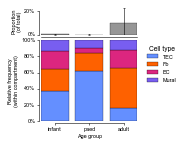

,age_group,mean_prop,sd_prop,n_donors
0,infant,0.003162,0.007545,19
1,paed,0.002595,0.000792,6
2,adult,0.104172,0.125999,13


In [15]:
# taa_l1: the four stromal compartments
fig, tot_l1, sub_l1 = population_stacked_plot(
    obs, col_cell_type='taa_l1', ctypes=ct_levels['taa_l1'], palette=palettes['taa_l1'],
    age_order=age_order, comp_values=stroma_comps,
    comp_sorts=MAIN_SORTS, tot_sorts=TOT_SORTS, min_cells=MIN_CELLS,
    figsize=calc_figsize(width=40, height=45),
    plt_path=f'{plot_path}/thyAgeing_stroma_taa_l1_relFreq_stackedbar_{today}.pdf',
    return_data=True)
plt.show()
sub_l1.to_csv(f'{results_path}/thyAgeing_stroma_taa_l1_stackedbar_{today}.csv', index=False)
tot_l1

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 37 samples / 23 donors passing >= 100 taa_l1 cells in sorts ['TOT', 'CD45N']
  donors per age group: infant=9, paed=3, adult=11


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


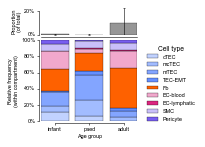

,age_group,taa_l2_v2,mean_prop,sd_prop,n_donors,rel_prop
0,infant,EC-blood,0.138614,0.098018,9,0.224572
1,infant,EC-lymphatic,0.004055,0.003759,9,0.006569
2,infant,Fb,0.167165,0.121763,9,0.270829
3,infant,Pericyte,0.025429,0.014247,9,0.041198
4,infant,SMC,0.054191,0.035451,9,0.087796


In [16]:
# taa_l2_v2
fig, tot_l2, sub_l2 = population_stacked_plot(
    obs, col_cell_type='taa_l2_v2', ctypes=ct_levels['taa_l2_v2'], palette=palettes['taa_l2_v2'],
    age_order=age_order, comp_values=stroma_comps,
    comp_sorts=MAIN_SORTS, tot_sorts=TOT_SORTS, min_cells=MIN_CELLS,
    figsize=calc_figsize(width=40, height=45),
    plt_path=f'{plot_path}/thyAgeing_stroma_taa_l2_v2_relFreq_stackedbar_{today}.pdf',
    return_data=True)
plt.show()
sub_l2.to_csv(f'{results_path}/thyAgeing_stroma_taa_l2_v2_stackedbar_{today}.csv', index=False)
sub_l2.head()

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 37 samples / 23 donors passing >= 100 taa_l1 cells in sorts ['TOT', 'CD45N']
  donors per age group: infant=9, paed=3, adult=11


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


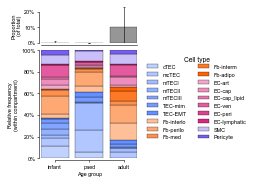

,age_group,taa_l3,mean_prop,sd_prop,n_donors,rel_prop
0,infant,EC-art,0.022926,0.020151,9,0.037143
1,infant,EC-cap,0.037405,0.030860,9,0.060601
2,infant,EC-cap_lipid,0.009542,0.013353,9,0.015459
3,infant,EC-lymphatic,0.004055,0.003759,9,0.006569
4,infant,EC-peri,0.000563,0.000674,9,0.000912


In [17]:
# taa_l3 (many cell types -> taller figure, two legend columns)
fig, tot_l3, sub_l3 = population_stacked_plot(
    obs, col_cell_type='taa_l3', ctypes=ct_levels['taa_l3'], palette=palettes['taa_l3'],
    age_order=age_order, comp_values=stroma_comps,
    comp_sorts=MAIN_SORTS, tot_sorts=TOT_SORTS, min_cells=MIN_CELLS,
    figsize=calc_figsize(width=40, height=60),
    legend_kwargs={'ncol': 2 if len(ct_levels['taa_l3']) > 16 else 1},
    plt_path=f'{plot_path}/thyAgeing_stroma_taa_l3_relFreq_stackedbar_{today}.pdf',
    return_data=True)
plt.show()
sub_l3.to_csv(f'{results_path}/thyAgeing_stroma_taa_l3_stackedbar_{today}.csv', index=False)
sub_l3.head()

### Consistency check

Summing the finer levels within each compartment must reproduce the `taa_l1` fractions.

In [18]:
ct2comp = (obs.loc[is_stroma, ['taa_l3', 'taa_l1']].astype(str).drop_duplicates()
           .set_index('taa_l3')['taa_l1'].to_dict())
l1 = sub_l1.pivot_table(index='age_group', columns='taa_l1', values='rel_prop', observed=False)
l3_by_comp = (sub_l3.assign(comp=sub_l3['taa_l3'].astype(str).map(ct2comp))
              .pivot_table(index='age_group', columns='comp', values='rel_prop', aggfunc='sum', observed=False))
l1.round(3)
l3_by_comp.round(3)
print('max |taa_l3 summed - taa_l1| =', float((l3_by_comp - l1).abs().max().max()))
print('stacks sum to (per age group):', sub_l3.groupby('age_group', observed=False)['rel_prop'].sum().round(6).to_dict())

taa_l1,EC,Fb,Mural,TEC
age_group,,,,
infant,0.231,0.271,0.129,0.369
paed,0.062,0.222,0.100,0.616
adult,0.221,0.487,0.124,0.168


comp,EC,Fb,Mural,TEC
age_group,,,,
infant,0.231,0.271,0.129,0.369
paed,0.062,0.222,0.100,0.616
adult,0.221,0.487,0.124,0.168


max |taa_l3 summed - taa_l1| = 1.1102230246251565e-16
stacks sum to (per age group): {'infant': 1.0, 'paed': 1.0, 'adult': 1.0}


## UMAP of the stromal cell types

Colours are the **same palette as the stacked bars** (`palettes[level]`). Embedding and plotting settings
follow `notebooks_github/08_TEC-EMT.ipynb`: the stroma subset gets its own embedding via
`utils_vk8.regen_embed` (`sc.pp.neighbors(use_rep='X_scVI')` + `sc.tl.umap(min_dist=0.1, spread=1)`), and
figures use `sc.settings.set_figure_params(dpi=80, color_map='RdPu')` with `frameon=False`,
`legend_fontsize=5`, `title=''`, saved with `bbox_inches='tight'`.

All stromal cells are shown regardless of sort - a UMAP is a per-cell view, not a composition estimate,
so the sort/`min_cells` filters that the bar plots need do not apply here. The coordinates are cached to
`results/` so re-runs skip the ~10 min neighbours+UMAP step.

In [19]:
%%time
# Stroma subset + its own embedding (same recipe as utils_vk8.regen_embed used in 08_TEC-EMT)
adata_stroma = adata[is_stroma.values].copy()
adata_stroma.obsm['X_umap_atlas'] = adata_stroma.obsm['X_umap'].copy()   # keep the atlas embedding too

umap_cache = f'{results_path}/thyAgeing_stroma_umap_coords.csv'
if os.path.exists(umap_cache):
    coords = pd.read_csv(umap_cache, index_col=0).reindex(adata_stroma.obs_names)
    assert coords.notna().all().all(), 'cached UMAP does not cover these cells - delete the cache and re-run'
    adata_stroma.obsm['X_umap'] = coords.values
    print('loaded cached stroma UMAP from', umap_cache)
else:
    sc.pp.neighbors(adata_stroma, use_rep='X_scVI')
    sc.tl.umap(adata_stroma, min_dist=0.1, spread=1)
    pd.DataFrame(adata_stroma.obsm['X_umap'], index=adata_stroma.obs_names,
                 columns=['UMAP1', 'UMAP2']).to_csv(umap_cache)
    print('computed and cached stroma UMAP ->', umap_cache)
adata_stroma

loaded cached stroma UMAP from /nfs/team205/vk8/projects/thymus_ageing_atlas/TEC_compartment/results/stroma_freq/thyAgeing_stroma_umap_coords.csv
CPU times: user 623 ms, sys: 31.3 ms, total: 654 ms
Wall time: 654 ms


AnnData object with n_obs × n_vars = 222928 × 35530
    obs: 'barcode', 'sample', 'library', 'index', 'library_tcr_ab', 'library_tcr_gd', 'library_bcr', 'path_raw_gex', 'starsolo_version', 'path_cellbender_gex', 'path_cellranger_arc', 'donor', 'chemistry_simple', 'chemistry_detail', 'chemistry_orig', 'origin_institute', 'research_no', 'study', 'sort', 'sort_type', 'in_HTSA', 'public_data', 'type', 'cite', 'health_status', 'age_group', 'age_group2', 'age', 'age_num', 'age_unit', 'age_cont', 'sex', 'age_months', 'path_tcr_ab', 'path_tcr_gd', 'path_bcr', 'comment', 'n_counts', 'n_genes', 'percent_mito', 'percent_ribo', 'percent_hb', 'scrublet_score', 'predicted_doublet', 'anno_status', 'qc_status', 'taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5'
    var: 'gene_id', 'gene_name'
    obsm: 'X_scVI', 'X_umap', 'X_umap_atlas'

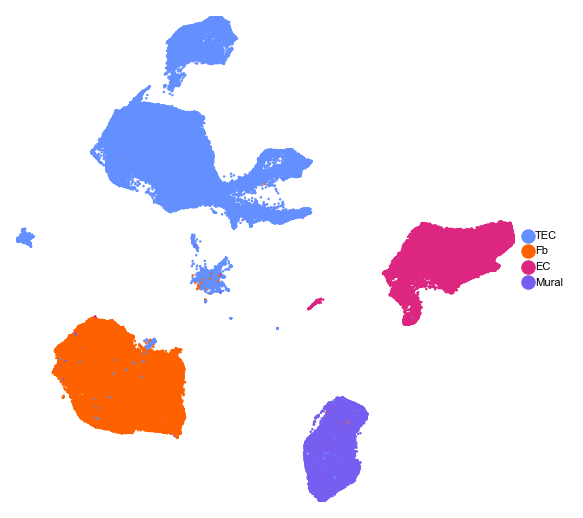

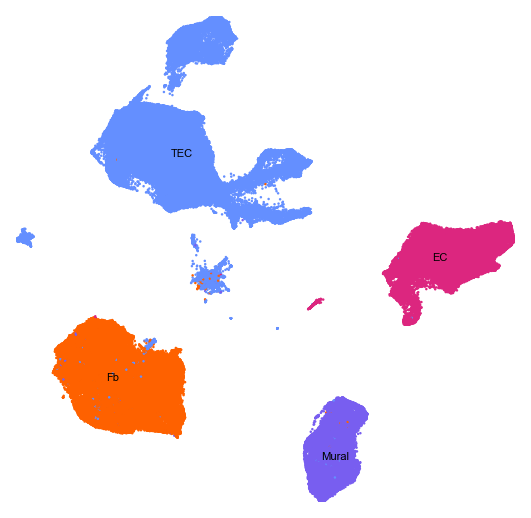

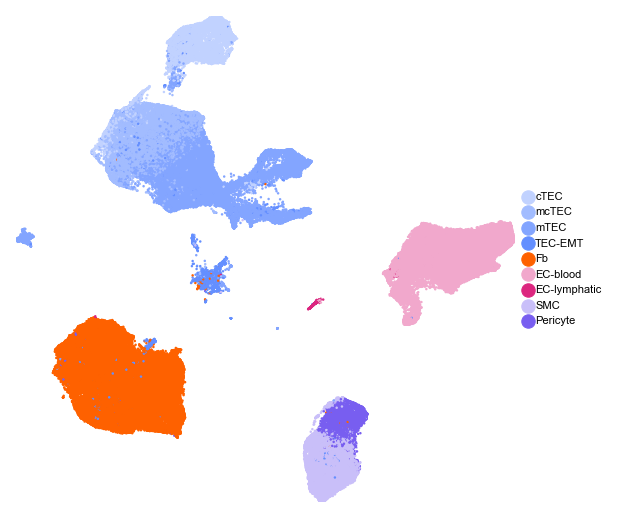

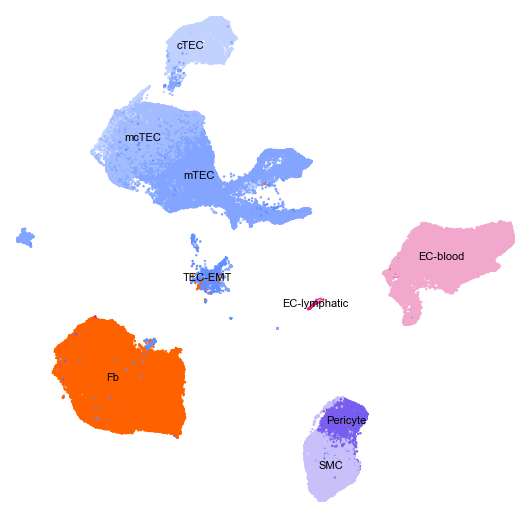

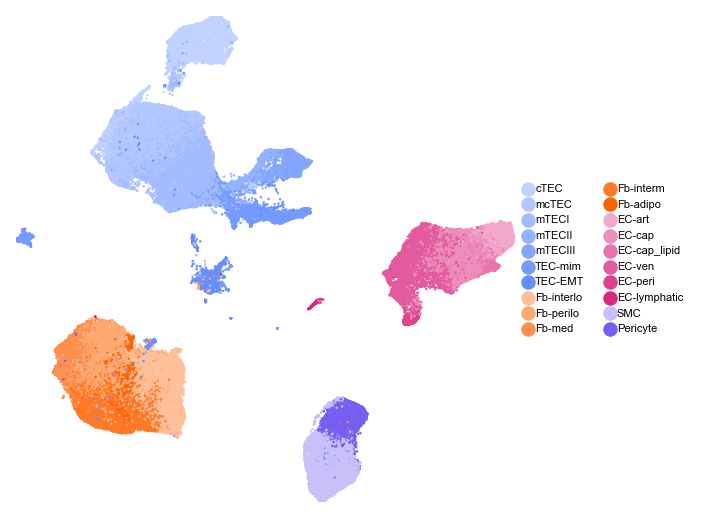

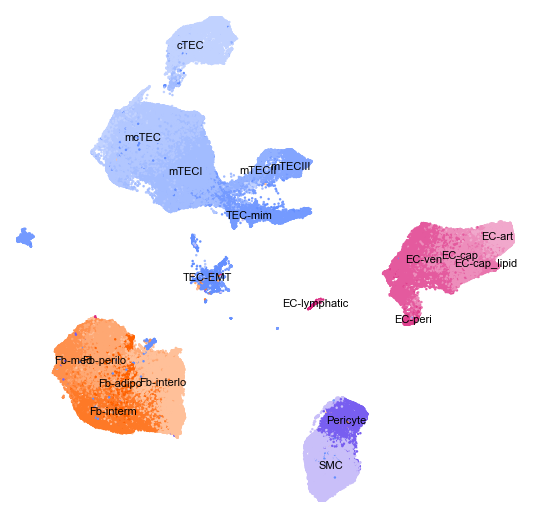

In [20]:
sc.settings.set_figure_params(dpi=80, color_map='RdPu')   # as in 08_TEC-EMT

# Order each level's categories as in the bar plots, then hand scanpy the matching colour list
for lvl in levels:
    cats = [c for c in ct_levels[lvl] if c in set(adata_stroma.obs[lvl].astype(str))]
    adata_stroma.obs[lvl] = pd.Categorical(adata_stroma.obs[lvl].astype(str), categories=cats, ordered=True)
    adata_stroma.uns[f'{lvl}_colors'] = [palettes[lvl][c] for c in cats]

for lvl in levels:
    for legend_loc, tag in [('right margin', 'legendRight'), ('on data', 'legendOnData')]:
        fig = sc.pl.umap(adata_stroma, color=lvl, palette=adata_stroma.uns[f'{lvl}_colors'],
                         size=5, frameon=False, legend_loc=legend_loc, legend_fontsize=5,
                         title='', return_fig=True)
        fig.savefig(f'{plot_path}/thyAgeing_stroma_{lvl}_umap_{tag}_{today}.pdf', bbox_inches='tight')
        fig.savefig(f'{plot_path}/thyAgeing_stroma_{lvl}_umap_{tag}_{today}.png', dpi=300, bbox_inches='tight')
        plt.show()

## Frequency change with age - quantification

Same machinery as `notebooks_github/03_Frequency_analysis_TEC_v3.ipynb`: per-donor frequencies with
`freq_by_donor` (proportion per sample, averaged over a donor's samples) and `plot_grouped_boxplot` with
`add_stats=True`, which runs a **Kruskal-Wallis test per cell type across age groups** and, where that is
significant (p < 0.05), a **post-hoc Dunn test** whose significant pairs are annotated on the plot.
`save_stats` writes `_summaryStats.csv`, `_kruskal.csv` and `_dunn.csv`.

Boxes use the pink/magenta tint palette (`get_tint_palette(thyAgeing_colors['magenta'])`), one tint per age
group, as in the `..._boxplot_pink.pdf` figures of that notebook. Frequencies are **within stroma** and use
the same donors/samples as the stacked bars (TOT + CD45N, >= 100 stromal cells), so the boxplots and the
bars describe the same quantity.

In [21]:
# Per-donor frequencies within stroma, from the same samples the stacked bars use
in_bracket = obs['sort'].astype(str).isin(list(MAIN_SORTS))
keep_samples = samples_passing(obs.loc[in_bracket], comp_col='taa_l1', comp_values=stroma_comps,
                               sample_col='sample', min_cells=MIN_CELLS)
anno_df = obs.loc[is_stroma & in_bracket & obs['sample'].isin(keep_samples)].copy()
for c in ['sample', 'donor'] + levels:
    if isinstance(anno_df[c].dtype, pd.CategoricalDtype):
        anno_df[c] = anno_df[c].cat.remove_unused_categories()
print(f'{anno_df.shape[0]:,} stromal cells / {anno_df["sample"].nunique()} samples / '
      f'{anno_df["donor"].nunique()} donors')

freq = {lvl: freq_by_donor(anno_df, sample_col='sample', donor_col='donor',
                           summary_col=lvl, add_meta=['age_group']) for lvl in levels}
for lvl, df in freq.items():
    df.to_csv(f'{results_path}/thyAgeing_stroma_{lvl}_byDonor_freq_{today}.csv', index=False)
freq['taa_l1'].head()

146,341 stromal cells / 37 samples / 23 donors


,donor,taa_l1,mean_prop,sd_prop,age_group
0,A16,EC,0.344799,0.043687,adult
1,A16,Fb,0.514924,0.051171,adult
2,A16,Mural,0.092201,0.052797,adult
3,A16,TEC,0.048076,0.026649,adult
4,A43,EC,0.304230,0.005617,adult


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:97: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby([x, hue]).agg(n_obs=(y, 'count'), mean=(y, lambda v: round(v.mean(), 4)), sd=(y, lambda v: round(v.std(), 4)), median=(y, lambda v: round(v.median(), 4))).to_csv(f'{save_stats}_summaryStats.csv', float_format='%.4f')
/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:156: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  g = sns.stripplot(data=data, x=x, y=y, order=order, dodge=True, jitter=True, hue=hue, hue_order=hue_order, size=1.5,


Performing Kruskal-Wallis and Dunn tests


<Axes: xlabel='Cell population', ylabel='Frequency'>

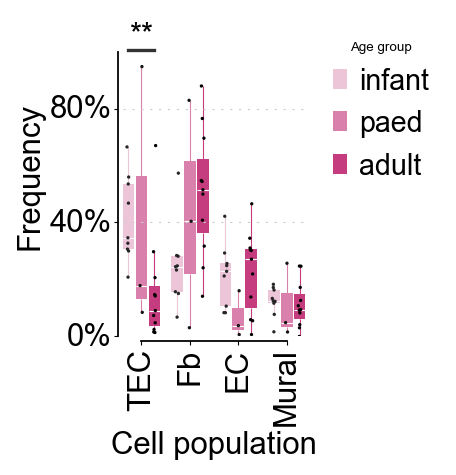

/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:97: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby([x, hue]).agg(n_obs=(y, 'count'), mean=(y, lambda v: round(v.mean(), 4)), sd=(y, lambda v: round(v.std(), 4)), median=(y, lambda v: round(v.median(), 4))).to_csv(f'{save_stats}_summaryStats.csv', float_format='%.4f')


Performing Kruskal-Wallis and Dunn tests


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:156: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  g = sns.stripplot(data=data, x=x, y=y, order=order, dodge=True, jitter=True, hue=hue, hue_order=hue_order, size=1.5,


<Axes: xlabel='Cell population', ylabel='Frequency'>

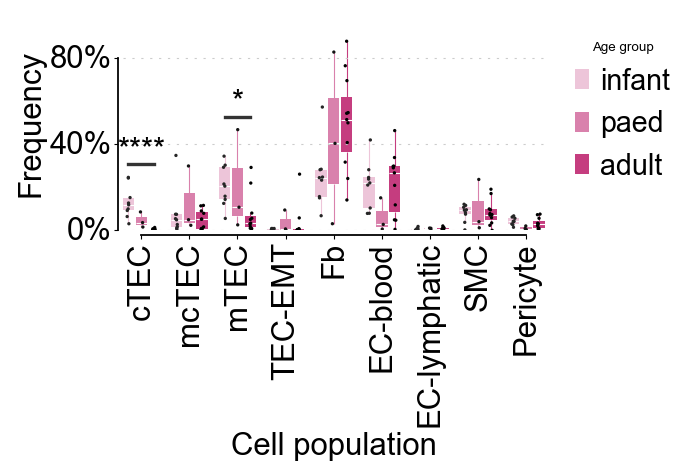

/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:97: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby([x, hue]).agg(n_obs=(y, 'count'), mean=(y, lambda v: round(v.mean(), 4)), sd=(y, lambda v: round(v.std(), 4)), median=(y, lambda v: round(v.median(), 4))).to_csv(f'{save_stats}_summaryStats.csv', float_format='%.4f')


Performing Kruskal-Wallis and Dunn tests


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:156: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  g = sns.stripplot(data=data, x=x, y=y, order=order, dodge=True, jitter=True, hue=hue, hue_order=hue_order, size=1.5,


<Axes: xlabel='Cell population', ylabel='Frequency'>

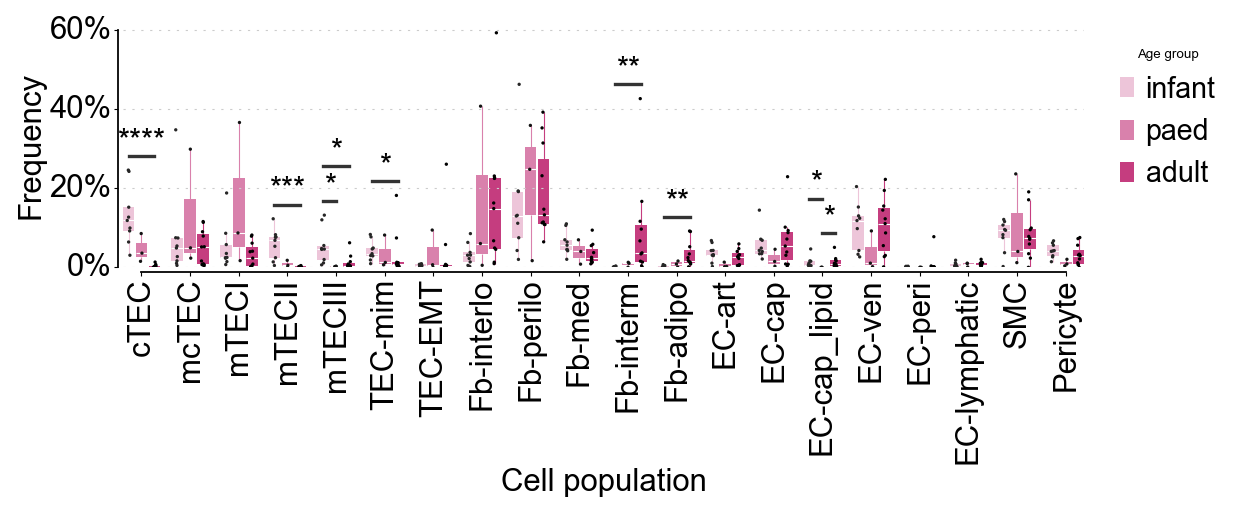

In [22]:
# Pink boxes, one tint per age group (as in 03_Frequency_analysis_TEC_v3 '..._boxplot_pink.pdf')
pink = get_tint_palette(thyAgeing_colors['magenta'], n=len(age_order), min_tint=0.3)
figsizes = {'taa_l1': (3.2, 3.2), 'taa_l2_v2': (4.6, 3.2), 'taa_l3': (8.0, 3.4)}
# legend outside the axes - inside it covers the right-most cell types
legend_kwargs = {'bbox_to_anchor': (1.01, 1), 'loc': 'upper left', 'frameon': False}

for lvl in levels:
    # drop stale stats from an earlier run so the summary below cannot read a leftover Dunn table
    for suffix in ['_kruskal.csv', '_dunn.csv', '_summaryStats.csv']:
        f = f'{results_path}/thyAgeing_stroma_{lvl}_freq{suffix}'
        if os.path.exists(f):
            os.remove(f)

    order = [c for c in ct_levels[lvl] if c in freq[lvl][lvl].astype(str).unique().tolist()]
    plot_grouped_boxplot(data=freq[lvl], x=lvl, y='mean_prop', hue='age_group',
                         order=order, hue_order=age_order,
                         x_label='Cell population', y_label='Frequency',   # frequencies are within stroma
                         legend_title='Age group', add_stats=True, format_percent=True,
                         figsize=figsizes[lvl], remove_legend=False, palette=pink,
                         legend_kwargs=legend_kwargs,
                         save_stats=f'{results_path}/thyAgeing_stroma_{lvl}_freq')
    plt.gca().yaxis.set_major_locator(plt.MaxNLocator(4))   # short axes - the default ticks overlap
    plt.savefig(f'{plot_path}/thyAgeing_stroma_{lvl}_freq_boxplot_pink_{today}.pdf', bbox_inches='tight')
    plt.show()


In [23]:
# Compact summary: median frequency per age group + Kruskal-Wallis per cell type (+ adult/infant ratio).
# NB Dunn p-values are FDR-BH adjusted within a cell type; the KW p-values are raw across cell types.
summary_freq = []
for lvl in levels:
    kw = pd.read_csv(f'{results_path}/thyAgeing_stroma_{lvl}_freq_kruskal.csv', index_col=0)
    med = (freq[lvl].pivot_table(index=lvl, columns='age_group', values='mean_prop',
                                 aggfunc='median', observed=False)
           .reindex([c for c in ct_levels[lvl] if c in freq[lvl][lvl].astype(str).unique().tolist()]))
    med.columns = [str(c) for c in med.columns]   # pivot_table gives a CategoricalIndex - it takes no new columns
    med.index = med.index.astype(str)
    kw.index = kw.index.astype(str)
    t = med.join(kw[['statistic', 'pvalue', 'pvalue_signif']]).rename_axis('cell_type')
    t.insert(0, 'level', lvl)
    t['adult_vs_infant'] = t['adult'] / t['infant']
    summary_freq.append(t)
summary_freq = pd.concat(summary_freq).reset_index()
summary_freq.to_csv(f'{results_path}/thyAgeing_stroma_freq_KWsummary_{today}.csv', index=False)
summary_freq.round(4)

dunn = [pd.read_csv(f'{results_path}/thyAgeing_stroma_{lvl}_freq_dunn.csv', index_col=0).assign(level=lvl)
        for lvl in levels if os.path.exists(f'{results_path}/thyAgeing_stroma_{lvl}_freq_dunn.csv')]
if dunn:
    dunn = pd.concat(dunn)
    dunn.loc[dunn['pvalue'] < 0.05].sort_values(['level', 'pvalue'])
else:
    print('no Dunn results - no cell type had a significant Kruskal-Wallis test')


,cell_type,level,infant,paed,adult,statistic,pvalue,pvalue_signif,adult_vs_infant
0,TEC,taa_l1,0.3464,0.1785,0.0908,9.1072,0.0105,*,0.2621
1,Fb,taa_l1,0.2448,0.4042,0.5149,5.0769,0.0790,NaN,2.1034
2,EC,taa_l1,0.2287,0.0381,0.2712,4.1388,0.1263,NaN,1.1859
3,Mural,taa_l1,0.1251,0.0486,0.0944,0.6258,0.7313,NaN,0.7542
4,cTEC,taa_l2_v2,0.1186,0.0359,0.0019,17.5739,0.0002,***,0.0163
5,mcTEC,taa_l2_v2,0.0489,0.0493,0.0517,0.4519,0.7978,NaN,1.0575
6,mTEC,taa_l2_v2,0.2054,0.1074,0.0331,7.4440,0.0242,*,0.1612
7,TEC-EMT,taa_l2_v2,0.0033,0.0065,0.0036,0.1338,0.9353,NaN,1.0906
8,Fb,taa_l2_v2,0.2448,0.4042,0.5149,5.0769,0.0790,NaN,2.1034
9,EC-blood,taa_l2_v2,0.2203,0.0275,0.2672,3.7273,0.1551,NaN,1.2126


,taa_l1,group1,group2,pvalue,pvalue_signif,level,taa_l2_v2,taa_l3
2,TEC,adult,infant,0.007958,**,taa_l1,NaN,NaN
2,NaN,adult,infant,0.000097,****,taa_l2_v2,cTEC,NaN
5,NaN,adult,infant,0.020564,*,taa_l2_v2,mTEC,NaN
14,NaN,adult,infant,0.000097,****,taa_l3,NaN,cTEC
17,NaN,adult,infant,0.000281,***,taa_l3,NaN,mTECII
5,NaN,adult,infant,0.001561,**,taa_l3,NaN,Fb-adipo
8,NaN,adult,infant,0.001963,**,taa_l3,NaN,Fb-interm
20,NaN,adult,infant,0.015898,*,taa_l3,NaN,mTECIII
19,NaN,paed,infant,0.015898,*,taa_l3,NaN,mTECIII
23,NaN,adult,paed,0.026164,*,taa_l3,NaN,EC-cap_lipid


## Sensitivity to the sort bracket

Same figures from (a) `CD45N` only, (b) the wider stroma-enriched bracket (`CD45N`, `CD45NCD3N`, `EPCAM`,
`EPCAM+CD205+`, `CD205+CD49F+`, `DGC`) and (c) `TOT` only. Saved with a `_sort<bracket>` suffix. Note no
paed `TOT` sample reaches 100 stromal cells, so the paed bar of the `TOT`-only figure is empty.

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 25 samples / 21 donors passing >= 100 taa_l1 cells in sorts ['CD45N', 'CD45NCD3N']
  donors per age group: infant=8, paed=3, adult=10


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l1 - CD45N sorts')

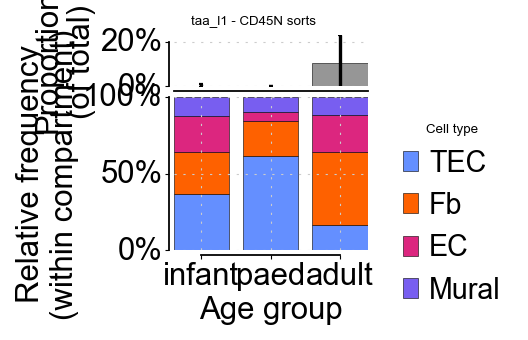

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 25 samples / 21 donors passing >= 100 taa_l1 cells in sorts ['CD45N', 'CD45NCD3N']
  donors per age group: infant=8, paed=3, adult=10


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l2_v2 - CD45N sorts')

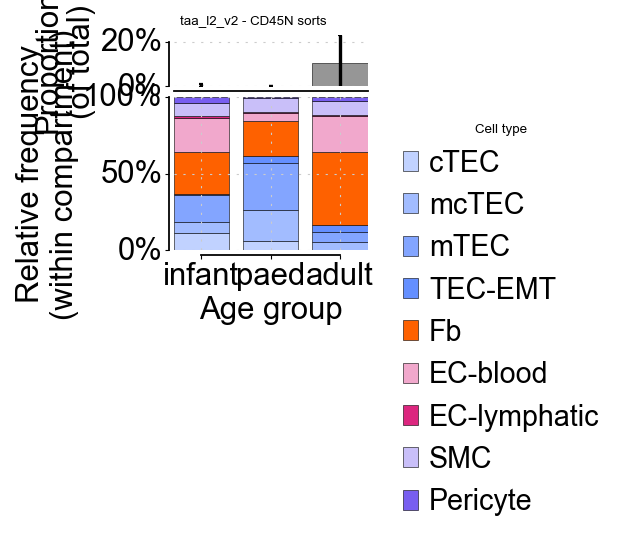

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 25 samples / 21 donors passing >= 100 taa_l1 cells in sorts ['CD45N', 'CD45NCD3N']
  donors per age group: infant=8, paed=3, adult=10


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l3 - CD45N sorts')

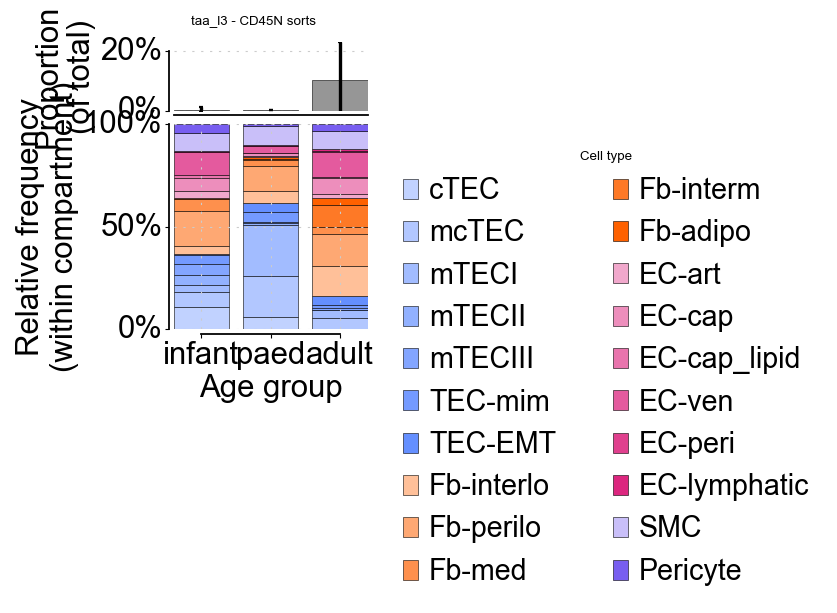

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 47 samples / 30 donors passing >= 100 taa_l1 cells in sorts ['CD45N', 'CD45NCD3N', 'EPCAM', 'EPCAM+CD205+', 'CD205+CD49F+', 'DGC']
  donors per age group: infant=14, paed=5, adult=11


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l1 - stromaEnriched sorts')

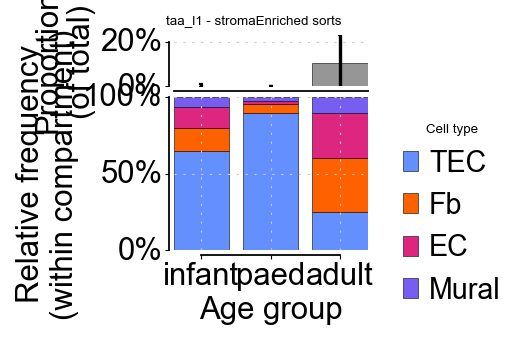

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 47 samples / 30 donors passing >= 100 taa_l1 cells in sorts ['CD45N', 'CD45NCD3N', 'EPCAM', 'EPCAM+CD205+', 'CD205+CD49F+', 'DGC']
  donors per age group: infant=14, paed=5, adult=11


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l2_v2 - stromaEnriched sorts')

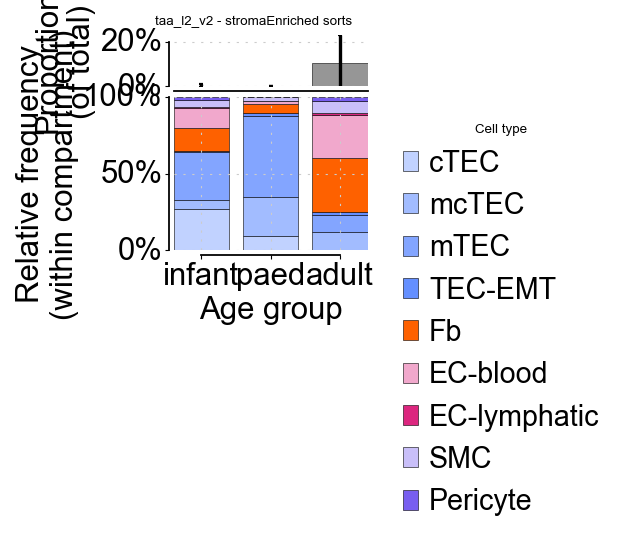

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 47 samples / 30 donors passing >= 100 taa_l1 cells in sorts ['CD45N', 'CD45NCD3N', 'EPCAM', 'EPCAM+CD205+', 'CD205+CD49F+', 'DGC']
  donors per age group: infant=14, paed=5, adult=11


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l3 - stromaEnriched sorts')

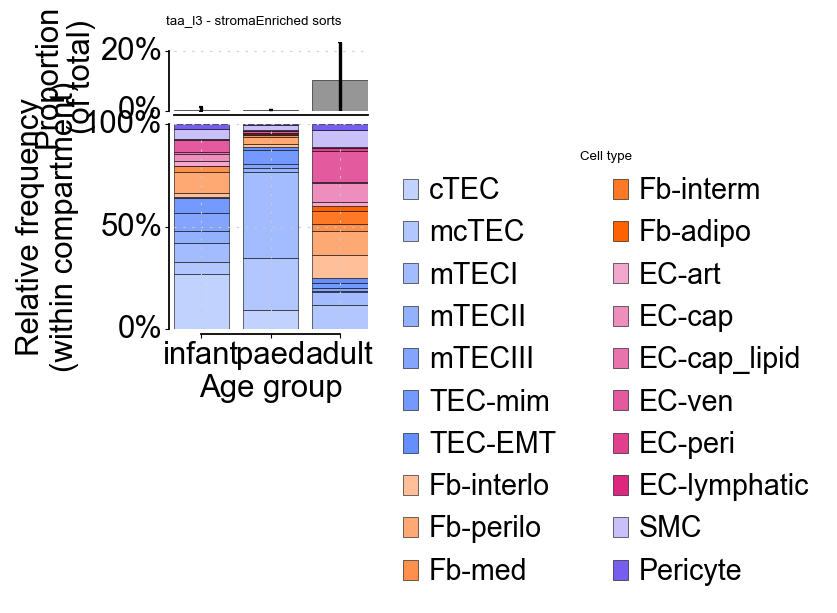

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 14 samples / 9 donors passing >= 100 taa_l1 cells in sorts ['TOT']
  donors per age group: infant=1, paed=0, adult=8


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l1 - TOT sorts')

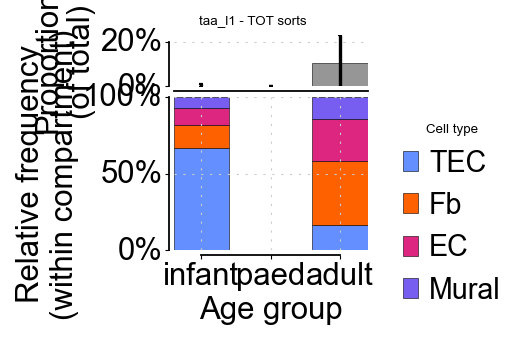

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 14 samples / 9 donors passing >= 100 taa_l1 cells in sorts ['TOT']
  donors per age group: infant=1, paed=0, adult=8


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l2_v2 - TOT sorts')

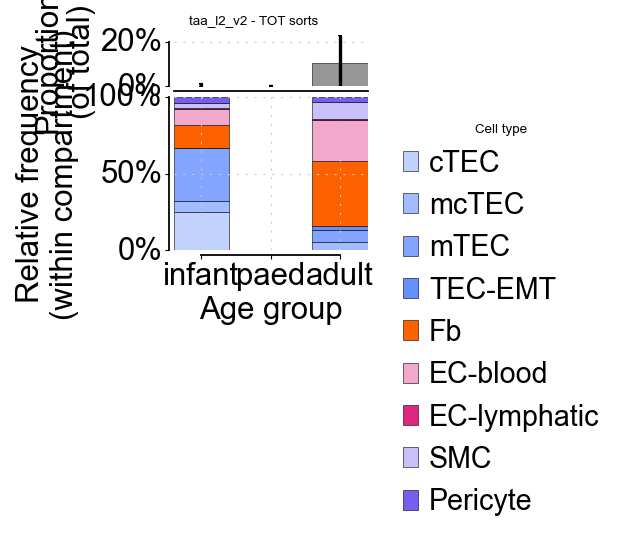

top panel: 64 samples / 38 donors from sorts ['TOT']


bottom panel: 14 samples / 9 donors passing >= 100 taa_l1 cells in sorts ['TOT']
  donors per age group: infant=1, paed=0, adult=8


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/scripts/plotting/pop_stacked.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Text(0.5, 0.98, 'taa_l3 - TOT sorts')

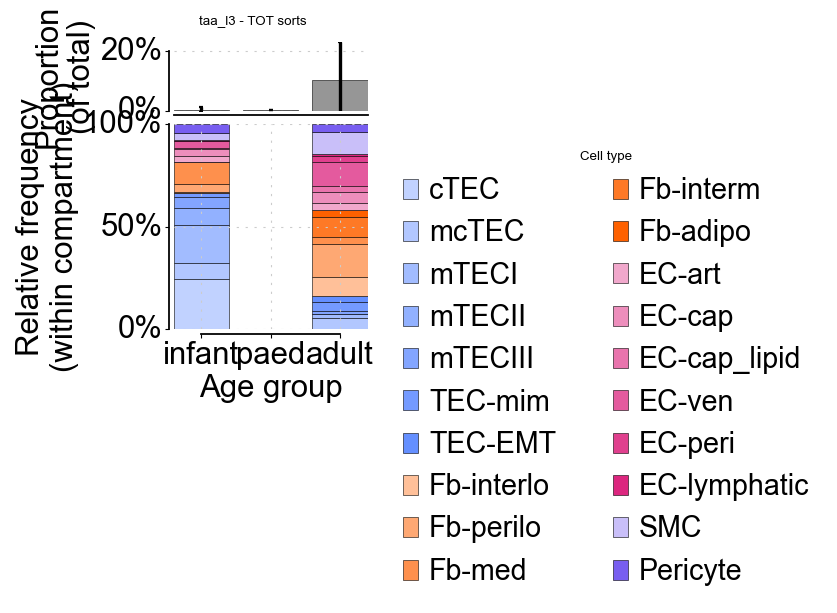

In [24]:
sort_brackets = {'CD45N': CD45N_SORTS, 'stromaEnriched': STROMA_ENRICHED_SORTS, 'TOT': TOT_SORTS}
comp_by_bracket = {'TOT+CD45N (main)': sub_l1.pivot_table(index='age_group', columns='taa_l1',
                                                          values='rel_prop', observed=False)}

for name, sorts in sort_brackets.items():
    for lvl in levels:
        try:
            fig, _, sub = population_stacked_plot(
                obs, col_cell_type=lvl, ctypes=ct_levels[lvl],
                age_order=age_order, comp_values=stroma_comps,
                comp_sorts=sorts, tot_sorts=TOT_SORTS, min_cells=MIN_CELLS,
                figsize=calc_figsize(width=40, height=60 if lvl == 'taa_l3' else 45),
                legend_kwargs={'ncol': 2 if len(ct_levels[lvl]) > 16 else 1},
                plt_path=f'{plot_path}/thyAgeing_stroma_{lvl}_relFreq_stackedbar_sort{name}_{today}.pdf',
                return_data=True)
            fig.suptitle(f'{lvl} - {name} sorts', fontsize=6)
            plt.show()
            sub.to_csv(f'{results_path}/thyAgeing_stroma_{lvl}_stackedbar_sort{name}_{today}.csv', index=False)
            if lvl == 'taa_l1':
                comp_by_bracket[name] = sub.pivot_table(index='age_group', columns='taa_l1',
                                                        values='rel_prop', observed=False)
        except ValueError as e:
            print(f'{name} / {lvl} skipped: {e}')

In [25]:
# taa_l1 composition per sort bracket, side by side
summary = pd.concat(comp_by_bracket, names=['sort_bracket']).round(3)
summary
summary.to_csv(f'{results_path}/thyAgeing_stroma_taa_l1_composition_bySortBracket_{today}.csv')

taa_l1                         EC     Fb  Mural    TEC
sort_bracket     age_group                            
TOT+CD45N (main) infant     0.231  0.271  0.129  0.369
                 paed       0.062  0.222  0.100  0.616
                 adult      0.221  0.487  0.124  0.168
CD45N            infant     0.232  0.272  0.129  0.367
                 paed       0.062  0.222  0.100  0.616
                 adult      0.236  0.479  0.121  0.164
stromaEnriched   infant     0.132  0.153  0.069  0.645
                 paed       0.020  0.059  0.030  0.891
                 adult      0.289  0.349  0.109  0.252
TOT              infant     0.107  0.150  0.077  0.666
                 adult      0.273  0.420  0.145  0.162